# Course 16: Algorithms Behind Modern AI
## Session 4: Computation graphs: topological sort and automatic differentiation

**Goal:** order a computation graph with Kahn's algorithm and with depth-first search, run reverse-mode differentiation as one backward sweep and check it against PyTorch, count the cost of walking every path instead, and shrink a graph with dead-code elimination, constant folding and common-subexpression elimination.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: a five-node graph and two topological orders
A computation is a **directed acyclic graph** (DAG). Each node is one value. An edge $u \to v$ means "$v$ is computed from $u$". Take

$$e = (a + b) \times (a \times b): \qquad c = a + b, \quad d = a \times b, \quad e = c \times d .$$

The inputs `a` and `b` each feed two nodes. This sharing is called **fan-out**, and it is why the graph is a DAG and not a tree.

A **topological order** lists the nodes so that every edge points forward: each value comes after its inputs. Two classic algorithms find one:

* **Kahn's algorithm** (Kahn 1962). Count the incoming edges of every node (its **in-degree**). Put the nodes with in-degree 0 in a queue. Take a node from the queue, write it down, and lower the in-degree of every node it feeds; a node that reaches 0 joins the queue.
* **Depth-first search (DFS).** From an unvisited node, follow edges as deep as possible. A node is *finished* when all the nodes it feeds are finished. The finishing order, reversed, is a topological order.

Both look at every node once and every edge once: $O(V + E)$ for $V$ nodes and $E$ edges, in every case.

On paper: (1) run Kahn's algorithm with the queue starting as `a, b`; (2) run DFS from `a`, visiting `c` before `d`, then from `b`, and reverse the finishing order; (3) with $a = 2$ and $b = 3$, compute `c`, `d`, `e`. Then run the cell. Its last lines add the edge `e -> a`, which makes a cycle: look at what each algorithm does then.

five-node graph: V = 5 nodes, E = 6 edges
Kahn's algorithm:            a b c d e | valid: True | steps: 11 = V + E
DFS, finishing order:        e c d a b
DFS, reversed:               b a d c e | valid: True | steps: 11 = V + E
values for a = 2, b = 3: c = 5, d = 6, e = 30

with the extra edge e -> a: Kahn's algorithm outputs 1 of 5 nodes (b); the rest wait on a cycle
DFS: cycle found: the edge e -> a leads back to an unfinished node


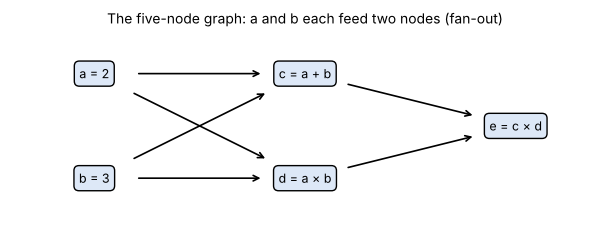

In [1]:
import math, random, time
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch

torch.set_num_threads(1)                 # torch is used only to check our gradients
t_start = time.time()

# the graph as a dictionary: node -> the nodes it feeds
G5 = {"a": ["c", "d"], "b": ["c", "d"], "c": ["e"], "d": ["e"], "e": []}

def kahn(adj):
    # Kahn's algorithm. Returns (order, steps). The order is shorter than the graph if there is a cycle.
    indeg = {u: 0 for u in adj}
    for u in adj:
        for v in adj[u]:
            indeg[v] += 1
    queue = deque(u for u in adj if indeg[u] == 0)
    order, steps = [], 0
    while queue:
        u = queue.popleft(); order.append(u); steps += 1        # one step for the node
        for v in adj[u]:
            steps += 1                                           # one step for the edge u -> v
            indeg[v] -= 1
            if indeg[v] == 0:
                queue.append(v)
    return order, steps

def dfs_order(adj):
    # depth-first search with an explicit stack. Returns (reversed finishing order, steps); raises ValueError on a cycle.
    NEW, OPEN, DONE = 0, 1, 2
    state = {u: NEW for u in adj}
    finished, steps = [], 0
    for root in adj:
        if state[root] != NEW:
            continue
        state[root] = OPEN; steps += 1
        stack = [(root, iter(adj[root]))]
        while stack:
            u, successors = stack[-1]
            for v in successors:
                steps += 1                                       # one step for the edge u -> v
                if state[v] == OPEN:                             # v is still on the stack: the edge closes a cycle
                    raise ValueError(f"cycle found: the edge {u} -> {v} leads back to an unfinished node")
                if state[v] == NEW:
                    state[v] = OPEN; steps += 1                  # one step for the node
                    stack.append((v, iter(adj[v])))
                    break
            else:                                                # no successor left: u is finished
                state[u] = DONE; finished.append(u); stack.pop()
    return finished[::-1], steps

def is_topological(adj, order):
    pos = {u: k for k, u in enumerate(order)}
    return len(order) == len(adj) and all(pos[u] < pos[v] for u in adj for v in adj[u])

V, E = len(G5), sum(len(vs) for vs in G5.values())
k_order, k_steps = kahn(G5)
d_order, d_steps = dfs_order(G5)
print(f"five-node graph: V = {V} nodes, E = {E} edges")
print("Kahn's algorithm:           ", " ".join(k_order), f"| valid: {is_topological(G5, k_order)} | steps: {k_steps} = V + E")
print("DFS, finishing order:       ", " ".join(d_order[::-1]))
print("DFS, reversed:              ", " ".join(d_order), f"| valid: {is_topological(G5, d_order)} | steps: {d_steps} = V + E")
a, b = 2, 3
c, d = a + b, a * b
print(f"values for a = {a}, b = {b}: c = {c}, d = {d}, e = {c * d}")

G_cycle = {u: list(vs) for u, vs in G5.items()}
G_cycle["e"].append("a")                                         # e -> a closes the cycle a -> c -> e -> a
order, _ = kahn(G_cycle)
print(f"\nwith the extra edge e -> a: Kahn's algorithm outputs {len(order)} of {len(G_cycle)} nodes ({' '.join(order)}); the rest wait on a cycle")
try:
    dfs_order(G_cycle)
except ValueError as err:
    print("DFS:", err)

pos = {"a": (0, 1), "b": (0, 0), "c": (1.5, 1), "d": (1.5, 0), "e": (3, 0.5)}
label = {"a": "a = 2", "b": "b = 3", "c": "c = a + b", "d": "d = a × b", "e": "e = c × d"}
fig, ax = plt.subplots(figsize=(6.2, 2.4))
for u in G5:
    for v in G5[u]:
        ax.annotate("", xy=pos[v], xytext=pos[u], arrowprops=dict(arrowstyle="->", shrinkA=32, shrinkB=32, lw=1.2))
    ax.text(*pos[u], label[u], ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round,pad=0.4", fc="#dde8f7", ec="k"))
ax.set_xlim(-0.6, 3.6); ax.set_ylim(-0.4, 1.4); ax.axis("off")
ax.set_title("The five-node graph: a and b each feed two nodes (fan-out)", fontsize=10)
plt.tight_layout(); plt.show()

### 2. A `Node` class for scalar expressions, and three ways to get an order
Now the graph is built by a program. A `Node` is an input, a constant, or the result of one operation: `+`, `×` or `tanh`. It remembers its operation and its **inputs** (pointers to other nodes). Writing `x * y + x` creates the nodes; nothing is computed yet.

Each node also gets a creation number. A node can only use nodes that already exist, so **the order of creation is already a topological order**, and a graph built this way cannot contain a cycle. A list of operations in the order in which a program ran them is called a **tape**. Frameworks that record operations while the program runs, such as PyTorch (Paszke et al. 2019), build their graphs in this way, so a valid order always exists.

`graph_of(outputs)` walks back from the outputs along the input pointers and collects every node they depend on, with the list of nodes each one feeds. On that graph we can run the two algorithms of section 1 unchanged.

The table checks the cost on random expression graphs of growing size: the steps of both algorithms must equal $V + E$ exactly. (Each new operation draws its inputs from the last six nodes, so values are shared a lot. The graphs are synthetic.)

In [2]:
class Node:
    # one value in a scalar expression graph
    tape = []                                                    # every node, in the order of creation
    def __init__(self, op, inputs=(), value=None, name=None):
        self.op, self.inputs, self.value, self.grad = op, tuple(inputs), value, 0.0
        self.id = len(Node.tape); Node.tape.append(self)         # creation number
        self.name = name if name is not None else f"v{self.id}"
    def __add__(self, other): return Node("add", (self, other))
    def __mul__(self, other): return Node("mul", (self, other))
    def tanh(self):           return Node("tanh", (self,))
    def __repr__(self):       return self.name

def graph_of(outputs):
    # every node the outputs depend on, as a dictionary: node -> the nodes it feeds (in creation order)
    seen, stack = set(), list(outputs)
    while stack:
        n = stack.pop()
        if n not in seen:
            seen.add(n); stack.extend(n.inputs)
    nodes = sorted(seen, key=lambda n: n.id)
    adj = {n: [] for n in nodes}
    for n in nodes:
        for i in n.inputs:
            adj[i].append(n)
    return adj

def random_dag(n_inputs, n_ops, rng, window=6):
    # a random expression: the first input of a new operation is one of the last `window` nodes;
    # the second one is, half of the time, one of the original inputs (this keeps the numbers in a healthy range)
    inputs = [Node("input", value=round(rng.uniform(-1, 1), 3), name=f"x{i}") for i in range(n_inputs)]
    nodes = list(inputs)
    for _ in range(n_ops):
        op, pool = rng.choice(["add", "mul", "tanh"]), nodes[-window:]
        if op == "tanh":
            nodes.append(rng.choice(pool).tanh())
        else:
            p = rng.choice(pool)
            q = rng.choice(inputs) if rng.random() < 0.5 else rng.choice(pool)
            nodes.append(p + q if op == "add" else p * q)
    return nodes                                                 # the last node is the output

# the five-node graph of section 1 again, now built by operators
a, b = Node("input", value=2.0, name="a"), Node("input", value=3.0, name="b")
c = a + b; c.name = "c"
d = a * b; d.name = "d"
e = c * d; e.name = "e"
adj5 = graph_of([e])
print("five-node graph built with operators; who feeds whom:", {repr(n): [repr(m) for m in adj5[n]] for n in adj5})
print("Kahn:", kahn(adj5)[0], "| DFS:", dfs_order(adj5)[0], "| the tape (creation order):", Node.tape)

rng = random.Random(4)
print(f"\n{'operations written':>18s} | {'V (needed)':>10s} | {'E':>7s} | {'V + E':>7s} | {'Kahn steps':>10s} | {'DFS steps':>9s} | all three orders valid")
for n_ops in [10, 100, 1_000, 10_000, 100_000]:
    Node.tape = []                                               # a new tape for every graph
    nodes = random_dag(4, n_ops, rng)
    adj = graph_of([nodes[-1]])
    V, E = len(adj), sum(len(vs) for vs in adj.values())
    (k_order, k_steps), (d_order, d_steps) = kahn(adj), dfs_order(adj)
    tape = [n for n in Node.tape if n in adj]                    # creation order, without the nodes the output does not need
    ok = is_topological(adj, k_order) and is_topological(adj, d_order) and is_topological(adj, tape)
    print(f"{n_ops:18,d} | {V:10,d} | {E:7,d} | {V + E:7,d} | {k_steps:10,d} | {d_steps:9,d} | {ok}")

five-node graph built with operators; who feeds whom: {'a': ['c', 'd'], 'b': ['c', 'd'], 'c': ['e'], 'd': ['e'], 'e': []}
Kahn: [a, b, c, d, e] | DFS: [b, a, d, c, e] | the tape (creation order): [a, b, c, d, e]

operations written | V (needed) |       E |   V + E | Kahn steps | DFS steps | all three orders valid
                10 |          5 |       4 |       9 |          9 |         9 | True
               100 |         56 |      86 |     142 |        142 |       142 | True
             1,000 |        519 |     846 |   1,365 |      1,365 |     1,365 | True
            10,000 |      5,351 |   8,944 |  14,295 |     14,295 |    14,295 | True


           100,000 |     53,594 |  89,374 | 142,968 |    142,968 |   142,968 | True


### 3. Forward in topological order, backward in the reverse order
**Forward:** go through the nodes in a topological order and compute each value from its inputs. One operation per node.

**Backward (reverse-mode differentiation):** we want $\partial\,\text{out} / \partial v$ for every node $v$; call it `v.grad`. Set `out.grad = 1`. Go through the nodes in **reverse** topological order. When we reach a node, every node it feeds has been handled, so its `grad` is complete. The node then sends `grad × (local derivative)` to each of its inputs, and an input **adds up** what it receives from all the nodes it feeds. One multiply–add per edge, so the whole sweep costs $E$ steps.

Course 2 session 5 derives the calculus (the chain rule, adjoints, forward and reverse mode) and builds an engine; here we only need the graph view. The local derivatives are: for $p + q$: 1 and 1; for $p \times q$: $q$ and $p$; for $\tanh p$: $1 - \tanh^2 p$.

By hand first, on the five-node graph: `e.grad = 1`; `c.grad = d = 6`; `d.grad = c = 5`; then `a.grad = c.grad × 1 + d.grad × b = 6 + 15 = 21` and `b.grad = c.grad × 1 + d.grad × a = 6 + 10 = 16`.

Then the cell builds random expression graphs and compares the gradients of all inputs with `torch.autograd`. It also counts the **paths** from the inputs to the output with the same backward sweep (send 1 along every edge instead of a derivative). The chain rule says that a gradient is a sum over all these paths; the sweep gets that sum without walking the paths one by one.

In [3]:
def forward(order):
    # compute every value; returns the number of operations
    ops = 0
    for n in order:
        if n.op == "add":    n.value = n.inputs[0].value + n.inputs[1].value; ops += 1
        elif n.op == "mul":  n.value = n.inputs[0].value * n.inputs[1].value; ops += 1
        elif n.op == "tanh": n.value = math.tanh(n.inputs[0].value); ops += 1
    return ops

def local_derivatives(n):
    if n.op == "add":  return (1.0, 1.0)
    if n.op == "mul":  return (n.inputs[1].value, n.inputs[0].value)
    if n.op == "tanh": return (1.0 - n.value ** 2,)
    return ()

def backward(order, output):
    # one sweep in reverse topological order; returns the number of edge steps
    for n in order:
        n.grad = 0.0
    output.grad = 1.0
    steps = 0
    for n in reversed(order):                    # every node that n feeds comes earlier in this loop
        for inp, dloc in zip(n.inputs, local_derivatives(n)):
            inp.grad += n.grad * dloc            # += : add up over the fan-out
            steps += 1
    return steps

def count_paths(order, output):
    # the same sweep with whole numbers: how many paths lead from each node to the output
    paths = {n: 0 for n in order}
    paths[output] = 1
    for n in reversed(order):
        for inp in n.inputs:
            paths[inp] += paths[n]
    return paths

def torch_gradients(order, output):
    # the same expression with torch scalars; returns {input node: gradient from torch.autograd}
    t = {}
    for n in order:
        if n.op == "input":  t[n] = torch.tensor(n.value, dtype=torch.float64, requires_grad=True)
        elif n.op == "const": t[n] = torch.tensor(n.value, dtype=torch.float64)
        elif n.op == "add":  t[n] = t[n.inputs[0]] + t[n.inputs[1]]
        elif n.op == "mul":  t[n] = t[n.inputs[0]] * t[n.inputs[1]]
        elif n.op == "tanh": t[n] = torch.tanh(t[n.inputs[0]])
    t[output].backward()
    return {n: t[n].grad.item() for n in order if n.op == "input"}, t[output].item()

order5, _ = kahn(adj5)
forward(order5); steps = backward(order5, e)
print("five-node graph: values", {n.name: n.value for n in order5})
print("                 grads ", {n.name: n.grad for n in order5}, f"| backward steps: {steps} = E")
tg, _ = torch_gradients(order5, e)
print("                 torch ", {n.name: g for n, g in tg.items()})

rng = random.Random(7)
print(f"\n{'ops written':>11s} | {'V':>4s} | {'E':>4s} | {'forward ops':>11s} | {'backward steps':>14s} | {'paths from inputs to output':>27s} | {'output':>9s} | {'largest gradient':>16s} | largest relative difference to torch")
for n_ops in [10, 20, 40, 80, 160, 320]:
    nodes = random_dag(5, n_ops, rng)
    out = nodes[-1]
    adj = graph_of([out])
    order, _ = kahn(adj)
    f_ops, b_steps = forward(order), backward(order, out)
    paths = count_paths(order, out)
    n_paths = sum(paths[n] for n in order if n.op == "input")
    tg, t_out = torch_gradients(order, out)
    assert abs(t_out - out.value) <= 1e-12 * max(1.0, abs(out.value))
    diff = max(abs(n.grad - g) / max(abs(n.grad), abs(g), 1e-300) for n, g in tg.items())
    g_max = max(abs(g) for g in tg.values())
    print(f"{n_ops:11d} | {len(adj):4d} | {sum(len(v) for v in adj.values()):4d} | {f_ops:11d} | {b_steps:14d} | {n_paths:27,d} | {out.value:9.5f} | {g_max:16.5f} | {diff:.1e}")
print(f"last graph: {b_steps} backward steps for {f_ops} forward operations, {b_steps / f_ops:.2f} per operation (never more than 2: an operation has at most two inputs)")

five-node graph: values {'a': 2.0, 'b': 3.0, 'c': 5.0, 'd': 6.0, 'e': 30.0}
                 grads  {'a': 21.0, 'b': 16.0, 'c': 6.0, 'd': 5.0, 'e': 1.0} | backward steps: 6 = E
                 torch  {'a': 21.0, 'b': 16.0}

ops written |    V |    E | forward ops | backward steps | paths from inputs to output |    output | largest gradient | largest relative difference to torch
         10 |    8 |    8 |           5 |              8 |                           4 |   0.26146 |          0.75616 | 1.3e-16
         20 |   15 |   21 |          12 |             21 |                          22 |   0.14245 |          1.00252 | 1.3e-16
         40 |   20 |   23 |          16 |             23 |                          10 |  -0.70396 |          1.00000 | 3.5e-16
         80 |   34 |   47 |          29 |             47 |                         106 |   0.00009 |          0.00363 | 4.8e-16
        160 |   95 |  149 |          90 |            149 |                      49,887 |  -0.76469 |      

### 4. The exponential trap: walking every path
The chain rule can also be read as a recursion: "the gradient of an input is the sum, over all paths to the output, of the product of the local derivatives along the path". Written directly, that is a function that calls itself for every input of a node, without remembering where it has been. On a tree this is fine. On a DAG it visits a shared node once **per path**.

The worst case is a **doubling chain**: $x_k = x_{k-1} + x_{k-1}$ for $k = 1 \dots n$. Each node feeds the next one twice, so there are $2^n$ paths from $x_n$ back to $x_0$, and the recursion makes $2^{n+1} - 1$ visits. The sweep of section 3 needs $2n$ edge steps. Every path contributes $1 \times 1 \times \dots = 1$, so the gradient is $2^n$: here the gradient *is* the number of paths.

This shape is not exotic. In a network with skip connections, each block's input reaches the block's output twice: directly, and through the layer. $n$ such blocks give $2^n$ paths.

The counts below are exact. The largest depth takes a few seconds of pure Python.

depth n | visits by path recursion |  2^(n+1) - 1 | sweep: edge steps |  2 n | gradient (both ways) |         2^n
      5 |                       63 |           63 |                10 |   10 |                   32 |          32
     10 |                    2,047 |        2,047 |                20 |   20 |                1,024 |       1,024
     15 |                   65,535 |       65,535 |                30 |   30 |               32,768 |      32,768


     20 |                2,097,151 |    2,097,151 |                40 |   40 |            1,048,576 |   1,048,576


     24 |               33,554,431 |   33,554,431 |                48 |   48 |           16,777,216 |  16,777,216
time at depth 24, path recursion: 7.34 s
time at depth 24, one backward sweep: 20 microseconds
depth 100: the sweep needs 200 edge steps; the path recursion would need 2^101 - 1 = 2,535,301,200,456,458,802,993,406,410,751 visits
torch.autograd on the depth-24 chain: gradient 16,777,216


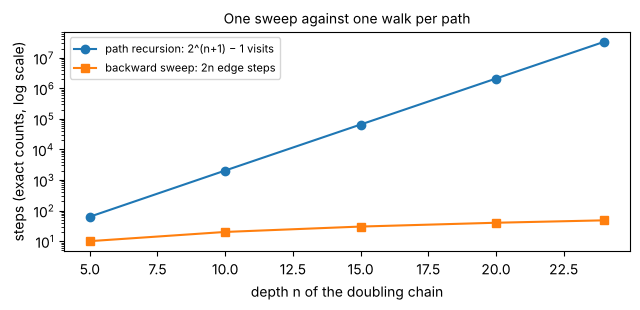

In [4]:
VISITS = [0]

def backward_by_paths(node, upstream):
    # the naive recursion: follow every path from the output down to the inputs
    VISITS[0] += 1
    if not node.inputs:
        node.grad += upstream
        return
    for inp, dloc in zip(node.inputs, local_derivatives(node)):
        backward_by_paths(inp, upstream * dloc)

def doubling_chain(n):
    x0 = Node("input", value=1.0, name="x0")
    x = x0
    for _ in range(n):
        x = x + x
    return x0, x

depths, visits, sweep_steps = [5, 10, 15, 20, 24], [], []
print(f"{'depth n':>7s} | {'visits by path recursion':>24s} | {'2^(n+1) - 1':>12s} | {'sweep: edge steps':>17s} | {'2 n':>4s} | {'gradient (both ways)':>20s} | {'2^n':>11s}")
for n in depths:
    x0, out = doubling_chain(n)
    order, _ = kahn(graph_of([out]))
    forward(order)
    t0 = time.perf_counter(); steps = backward(order, out); t_sweep = time.perf_counter() - t0
    g_sweep = x0.grad
    x0.grad = 0.0; VISITS[0] = 0
    t0 = time.perf_counter(); backward_by_paths(out, 1.0); t_paths = time.perf_counter() - t0
    assert g_sweep == x0.grad == 2 ** n
    visits.append(VISITS[0]); sweep_steps.append(steps)
    print(f"{n:7d} | {VISITS[0]:24,d} | {2 ** (n + 1) - 1:12,d} | {steps:17d} | {2 * n:4d} | {x0.grad:20,.0f} | {2 ** n:11,d}")
print(f"time at depth {depths[-1]}, path recursion: {t_paths:.2f} s")
print(f"time at depth {depths[-1]}, one backward sweep: {t_sweep * 1e6:.0f} microseconds")
print(f"depth 100: the sweep needs 200 edge steps; the path recursion would need 2^101 - 1 = {2 ** 101 - 1:,d} visits")

xt = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)
yt = xt
for _ in range(depths[-1]):
    yt = yt + yt
yt.backward()
print(f"torch.autograd on the depth-{depths[-1]} chain: gradient {xt.grad.item():,.0f}")

plt.figure(figsize=(6.5, 3.2))
plt.semilogy(depths, visits, "o-", label="path recursion: 2^(n+1) − 1 visits")
plt.semilogy(depths, sweep_steps, "s-", label="backward sweep: 2n edge steps")
plt.xlabel("depth n of the doubling chain"); plt.ylabel("steps (exact counts, log scale)")
plt.title("One sweep against one walk per path", fontsize=10); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5. Three passes a compiler runs on the graph
A graph that is known before it runs can be made smaller first. Three standard passes, each one a graph algorithm you already know:

* **Dead-code elimination:** a node is *live* if an output depends on it. Search backwards from the outputs along the input pointers (reachability, $O(V + E)$) and drop everything that was not reached.
* **Constant folding:** go through the nodes in topological order. If every input of an operation is a constant, compute the result now and store it as a constant.
* **Common-subexpression elimination (CSE):** two nodes with the same operation and the same inputs compute the same value. Go through the nodes in topological order and keep a dictionary from the key `(operation, ids of the inputs)` to the first node with that key; a later node with the same key is replaced by the first one. For `+` and `×` the two ids are sorted first, so `p + q` and `q + p` get the same key. Constants with equal values are merged in the same way. This is session 2's hash table at work: one expected $O(1)$ lookup per node.

The program below is a small network written without care: 4 inputs, 3 hidden units, 1 output,

$$y = \sum_j v_j \tanh\Big(b_j + \sum_i w_{ji}\, z_i\Big), \qquad z_i = (x_i - \text{mean}) \times (\text{scale}_1 \times \text{scale}_2).$$

The weights are constants. The programmer typed the normalization $z_i$ again inside the loop over the hidden units, computed $\text{scale}_1 \times \text{scale}_2$ again at every use, and left a debugging value in the code that nothing reads. Every literal constant in the program text becomes its own node.

Before running: how many operations does the network really need? Count the $z_i$, the products and sums of each hidden unit, the `tanh`s, and the output sum. After every pass the cell evaluates the output again: it must not change by a single bit.

In [5]:
COMMUTATIVE = ("add", "mul")

def apply_op(op, vals):
    return vals[0] + vals[1] if op == "add" else vals[0] * vals[1] if op == "mul" else math.tanh(vals[0])

def careless_network(xs, W, bias, V, mean=0.25, scale1=4.0, scale2=0.5):
    C = lambda v: Node("const", value=v)                         # every literal constant in the text is a new node
    y = None
    for j in range(len(W)):                                      # one hidden unit after the other
        s = C(bias[j])
        for i, x in enumerate(xs):
            z = (x + C(-mean)) * (C(scale1) * C(scale2))         # the normalization, typed again for every hidden unit
            s = s + z * C(W[j][i])
        term = s.tanh() * C(V[j])
        y = term if y is None else y + term
    sq = None                                                    # left over from debugging: computed, never used
    for x in xs:
        z = (x + C(-mean)) * (C(scale1) * C(scale2))
        sq = z * z if sq is None else sq + z * z
    debug = sq.tanh()
    return y

def dead_code_elimination(nodes, outputs):
    live, stack = set(), list(outputs)                           # reachability, backwards from the outputs
    while stack:
        n = stack.pop()
        if n not in live:
            live.add(n); stack.extend(n.inputs)
    return [n for n in nodes if n in live], outputs

def rewrite(nodes, outputs, fold=False, cse=False):
    # one pass in topological order; builds a new graph and returns (new nodes, new outputs)
    new_of, table, out = {}, {}, []                              # old node -> new node; CSE key -> new node
    for n in nodes:
        ins = tuple(new_of[i] for i in n.inputs)
        op, value = n.op, n.value if not ins else None
        if fold and ins and all(i.op == "const" for i in ins):   # constant folding: compute it now
            op, value, ins = "const", apply_op(n.op, [i.value for i in ins]), ()
        key = None
        if cse:
            if op == "input":   key = ("input", n.name)
            elif op == "const": key = ("const", value)
            else:
                ids = [i.id for i in ins]
                key = (op, tuple(sorted(ids)) if op in COMMUTATIVE else tuple(ids))
        if key is not None and key in table:
            new_of[n] = table[key]                               # seen before: reuse the first node
        else:
            m = Node(op, ins, value, name=n.name if op == "input" else None)
            new_of[n] = m; out.append(m)
            if key is not None:
                table[key] = m
    return out, [new_of[o] for o in outputs]

def report(stage, nodes, outputs, reference=None):
    n_run = forward(nodes)                                       # the node list is in topological order
    vals = [o.value for o in outputs]
    b_steps = backward(nodes, outputs[0])
    grads = [n.grad for n in nodes if n.op == "input"]
    same = "" if reference is None else f" | output and gradient unchanged: {vals == reference[0]} {grads == reference[1]}"
    n_const = sum(n.op == "const" for n in nodes)
    print(f"{stage:38s} | {len(nodes):5d} | {n_const:9d} | {n_run:10d} | {b_steps:14d}{same}")
    return vals, grads

rng = random.Random(11)
n_in, n_hid = 4, 3
Node.tape = []
xs = [Node("input", value=round(rng.uniform(-1, 1), 3), name=f"x{i}") for i in range(n_in)]
W = [[round(rng.uniform(-1, 1), 2) for _ in range(n_in)] for _ in range(n_hid)]
bias, Vw = [round(rng.uniform(-1, 1), 2) for _ in range(n_hid)], [round(rng.uniform(-1, 1), 2) for _ in range(n_hid)]
y = careless_network(xs, W, bias, Vw)
prog, outs = list(Node.tape), [y]                                # the program as written: the whole tape

print(f"{'stage':38s} | nodes | constants | operations | backward steps")
ref = report("program as written", prog, outs)
g1, o1 = dead_code_elimination(prog, outs);                      report("1. dead-code elimination", g1, o1, ref)
g2, o2 = rewrite(g1, o1, fold=True);                             report("2. constant folding", g2, o2, ref)
g2, o2 = dead_code_elimination(g2, o2);                          report("   and dead-code elimination again", g2, o2, ref)
g3, o3 = rewrite(g2, o2, cse=True);                              report("3. common-subexpression elimination", g3, o3, ref)
g4, o4 = dead_code_elimination(*rewrite(g3, o3, fold=True, cse=True)); report("   all three passes once more", g4, o4, ref)
print(f"output y = {ref[0][0]:.12f}; gradient for the inputs: {[round(g, 6) for g in ref[1]]}")
adj = graph_of(o3)
print(f"the final graph: V = {len(adj)}, E = {sum(len(v) for v in adj.values())}; largest fan-out of an operation result: "
      f"{max(len(v) for n, v in adj.items() if n.inputs)} (each z feeds all {n_hid} hidden units)")
print(f"operations counted by hand: {2 * n_in} for the z, {2 * n_in * n_hid} to multiply by w and add, {2 * n_hid} for tanh and v, {n_hid - 1} to add up the output = {2 * n_in + 2 * n_in * n_hid + 2 * n_hid + n_hid - 1}")

stage                                  | nodes | constants | operations | backward steps
program as written                     |   158 |        66 |         88 |            172
1. dead-code elimination               |   126 |        54 |         68 |            133 | output and gradient unchanged: True True
2. constant folding                    |   126 |        66 |         56 |            109 | output and gradient unchanged: True True
   and dead-code elimination again     |   102 |        42 |         56 |            109 | output and gradient unchanged: True True
3. common-subexpression elimination    |    63 |        19 |         40 |             77 | output and gradient unchanged: True True
   all three passes once more          |    63 |        19 |         40 |             77 | output and gradient unchanged: True True
output y = -0.799785885540; gradient for the inputs: [-0.169403, -0.857607, 0.733366, 0.735561]
the final graph: V = 63, E = 77; largest fan-out of an operation r

### 6. Memory planning: reference counts, and why the order matters
While a graph runs, a value must stay in memory until the last node that reads it has run. A runtime can know this in advance: give every value a **reference count**, the number of nodes that read it (plus one if it is an output). Run the nodes in a topological order; after each node, lower the count of its inputs and free an input whose count reaches zero. The largest number of values alive at the same moment is the **peak memory**, here counted in values.

Different valid orders give different peaks. The first graph below has one input $x$, eight branches $f_b(x)$ of four operations each, and a running sum $s = f_1 + f_2 + \dots + f_8$. We compare two orders:

* **Kahn's order** (breadth-first): the first operation of every branch, then the second of every branch, and so on. All eight branches are open at once.
* **Depth-first from the output:** walk back from the output along the input pointers and write a node down when all its inputs are written. This finishes one branch and adds it to the sum before it starts the next. (micrograd, the small engine that Course 2 session 5 uses, sorts its graph this way.)

We count only the results of operations; inputs and constants stay in memory anyway. The last lines do the same for the optimized network of section 5. Course 11 session 8 does this accounting in bytes for a CNN on a phone.

branch graph: 39 operations, 48 nodes
Kahn (breadth-first)        : output 0.525843 | peak number of live values: 9
depth-first from the output : output 0.525843 | peak number of live values: 3


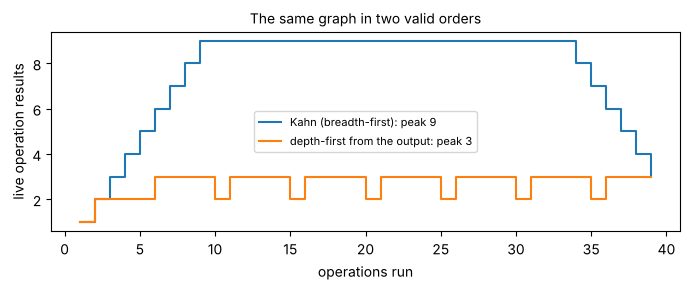

branches k =  2: peak with Kahn's order  3, depth-first from the output 3
branches k =  4: peak with Kahn's order  5, depth-first from the output 3
branches k =  8: peak with Kahn's order  9, depth-first from the output 3
branches k = 16: peak with Kahn's order 17, depth-first from the output 3
branches k = 32: peak with Kahn's order 33, depth-first from the output 3
optimized network of section 5 (40 operations): peak with Kahn's order 13, depth-first from the output 8, order of the tape 8
runtime so far 9 s


In [6]:
def order_from_output(outputs):
    # depth-first search along the input pointers; a node is written down when all its inputs are written
    order, seen = [], set()
    for root in outputs:
        if root in seen:
            continue
        seen.add(root)
        stack = [(root, iter(root.inputs))]
        while stack:
            n, inputs = stack[-1]
            for i in inputs:
                if i not in seen:
                    seen.add(i); stack.append((i, iter(i.inputs)))
                    break
            else:
                order.append(n); stack.pop()
    return order

def live_trace(order, outputs):
    # run the order with reference counts; returns the number of live operation results while each operation runs
    refs = {n: 0 for n in order}
    for n in order:
        for i in n.inputs:
            refs[i] += 1
    for o in outputs:
        refs[o] += 1                                             # an output is never freed
    live, trace = 0, []
    for n in order:
        if not n.inputs:
            continue                                             # inputs and constants are not counted
        live += 1; trace.append(live)                            # the result is allocated while its inputs are still alive
        for i in n.inputs:
            refs[i] -= 1
            if refs[i] == 0 and i.inputs:
                live -= 1                                        # the last reader has run: free it
    return trace

def branches(k=8, depth=4):
    x = Node("input", value=0.3, name="x")
    total = None
    for b in range(k):
        h = x * Node("const", value=0.5 + 0.1 * b)               # a different constant in every branch
        for j in range(depth - 1):
            h = h.tanh() if j % 2 == 0 else h * h
        total = h if total is None else total + h
    return x, total

x, total = branches()
adj = graph_of([total])
orders = {"Kahn (breadth-first)": kahn(adj)[0], "depth-first from the output": order_from_output([total])}
print(f"branch graph: {sum(1 for n in adj if n.inputs)} operations, {len(adj)} nodes")
plt.figure(figsize=(7, 3.0))
for name, order in orders.items():
    assert is_topological(adj, order)
    forward(order)
    trace = live_trace(order, [total])
    print(f"{name:28s}: output {total.value:.6f} | peak number of live values: {max(trace)}")
    plt.step(range(1, len(trace) + 1), trace, where="post", label=f"{name}: peak {max(trace)}")
plt.xlabel("operations run"); plt.ylabel("live operation results")
plt.title("The same graph in two valid orders", fontsize=10); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

for k in [2, 4, 8, 16, 32]:
    x_k, total_k = branches(k=k)
    adj_k = graph_of([total_k])
    print(f"branches k = {k:2d}: peak with Kahn's order {max(live_trace(kahn(adj_k)[0], [total_k])):2d}, "
          f"depth-first from the output {max(live_trace(order_from_output([total_k]), [total_k]))}")

adj_net = graph_of(o3)
peaks = [max(live_trace(order, o3)) for order in (kahn(adj_net)[0], order_from_output(o3), g3)]
print(f"optimized network of section 5 ({sum(1 for n in adj_net if n.inputs)} operations): peak with Kahn's order {peaks[0]}, "
      f"depth-first from the output {peaks[1]}, order of the tape {peaks[2]}")
print(f"runtime so far {time.time() - t_start:.0f} s")

### 7. Exercises

In [7]:
# TODO: operator fusion. A product p * q that feeds exactly one node, where that node is an addition, can be merged with it
# into ONE node muladd(p, q, r) = p * q + r. Write count_fusable(outputs): the number of additions in a graph that can absorb
# a product in this way. Use graph_of() to get the fan-out of every node. Rules: an addition absorbs at most one product,
# and an output node must stay. Run it on the optimized network (o3). How many operations are left after fusion?
def count_fusable(outputs):
    return None          # replace with your code

r = count_fusable(o3)
print("not done yet" if r is None else r)

not done yet


In [8]:
# TODO: all_orders(adj) should return every topological order of a small graph, by backtracking: at each step, choose any
# node whose inputs have all been placed. Use it on branches(k=3, depth=2): how many valid orders are there, what are the
# smallest and the largest peak (use live_trace), and how many orders reach the smallest peak?
def all_orders(adj):
    return None          # replace with your code

x3, total3 = branches(k=3, depth=2)
r = all_orders(graph_of([total3]))
print("not done yet" if r is None else len(r))

not done yet


### What to notice
(Written from the run above. The counts are exact and will be the same on your machine; the two timings will not.)

1. **Two algorithms, two different valid orders.** On the five-node graph Kahn's algorithm gave `a b c d e` and depth-first search gave `b a d c e`. Both are topological orders, and both needed 11 steps, which is $V + E = 5 + 6$. With the extra edge `e -> a`, Kahn's algorithm wrote down only 1 of the 5 nodes (`b`): a node on a cycle never reaches in-degree 0. Depth-first search named the edge that closes the cycle.
2. **The cost is $V + E$, and the tape is free.** For every random graph, up to 100,000 written operations (53,594 needed nodes and 89,374 edges), both algorithms took exactly $V + E$ steps (142,968). The order of creation was also a valid order every time: a program that builds its graph by running never needs to sort it.
3. **One backward sweep gives every gradient.** By hand and in code the five-node graph gave `a.grad = 21` and `b.grad = 16`, and `torch.autograd` returned the same numbers. On the random graphs our gradients differed from PyTorch's by at most 6.4e-16 (relative): rounding only. The sweep did one step per edge: 356 steps for the largest graph, 1.74 per forward operation. That graph has 15,876,473,600,972 paths from its inputs to its output, and the gradient is a sum over all of them.
4. **Walking the paths is exponential.** On the doubling chain the recursion made exactly $2^{n+1} - 1$ visits: 63 at depth 5 and 33,554,431 at depth 24, where the sweep made 48 edge steps. Both gave the same gradient, $2^{24} = 16{,}777{,}216$, and so did PyTorch. In this run the recursion took several seconds and the sweep a few tens of microseconds. The naive recursion is not wrong; it repeats the work of every shared node once per path.
5. **Three small passes removed more than half of the careless network.** Dead-code elimination removed the debugging value (88 to 68 operations). Constant folding computed the 12 products of the two scale constants in advance (68 to 56). Common-subexpression elimination kept one copy of each $z_i$ instead of three and merged equal constants (56 to 40 operations, 158 to 63 nodes). 40 is the number you count by hand. The output and the gradient did not change by a single bit, and the backward sweep became cheaper too: 172 edge steps before, 77 after. A second round of all passes changed nothing.
6. **The order decides the peak memory.** For eight branches, Kahn's order kept 9 results alive at its peak and the depth-first order from the output kept 3. With $k$ branches the first grows as $k + 1$ and the second stays at 3. For two branches both gave 3, so breadth-first is not always worse. On the optimized network the peaks were 13 and 8; the order of the tape also gave 8.
7. These graphs hold single numbers. In a real model each node is a tensor with millions of entries, the peak is counted in bytes (Course 11 session 8), and a runtime also fuses nodes and chooses kernels (Course 11 session 7). The graph algorithms are the same ones.